# LAB 12 — Artificial Neural Networks: The Perceptron
## Student Information
- **Name: Eshwar Lal**
- **Roll No: 023-24-0186**
- **Section: F**
- **Date: 22/11/2026**

**Dataset:** Iris (sklearn built-in)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.datasets import make_classification

np.random.seed(42)
iris = load_iris()
print("Iris loaded:", iris.data.shape, "| Classes:", iris.target_names)


Iris loaded: (150, 4) | Classes: ['setosa' 'versicolor' 'virginica']


## Part 0 — Key Concepts
Read the definitions table in the lab manual before starting.

## Part 1 — The Neuron From Scratch

### 1.1 Weighted Sum and Step Function
**Task 1.1** — Implement `weighted_sum`, `step_function`, and `predict`. Verify with slide 16.

In [2]:
# Task 1.1
def weighted_sum(w,x,b):
    return np.dot(w,x)+b
def step_function(z):
    return 1 if z>=0 else 0
def predict(w,x,b):
    return step_function(weighted_sum(w,x,b))
w=[0.6,0.8]
x=[2,3]
b=-2
print("Prediction:",predict(w,x,b))
w=[1,-0.5]
b=0.5
inputs=[[1,1],[2,1],[0,3]]
for x in inputs:
    print("Input:",x,"Prediction:",predict(w,x,b))



Prediction: 1
Input: [1, 1] Prediction: 1
Input: [2, 1] Prediction: 1
Input: [0, 3] Prediction: 0


### 1.2 One Manual Weight Update
**Task 1.2** — Complete one full epoch on the AND gate. Start: w=[0.2,−0.1], b=0, η=0.1.

In [3]:
# Task 1.2 — AND gate: X=[[0,0],[0,1],[1,0],[1,1]], y=[0,0,0,1]
w=np.array([0.2,-0.1])
b=0
eta=0.1
data=[([0,0],0),([0,1],0),([1,0],0),([1,1],1)]
mistakes=0
for x,y in data:
    z=np.dot(w,x)+b
    y_hat=1 if z>=0 else 0
    e=y-y_hat
    print("Input:",x,"Actual:",y,"z:",z,"Predicted:",y_hat,"Error:",e)
    if e!=0:
        mistakes+=1
        w=w+eta*e*np.array(x)
        b=b+eta*e
    print("Updated w:",w,"Updated b:",b)
print("Final weights:",w)
print("Final bias:",b)
print("Total mistakes:",mistakes)
if mistakes==0:
    print("Converged!")
else:
    print("Keep training.")

Input: [0, 0] Actual: 0 z: 0.0 Predicted: 1 Error: -1
Updated w: [ 0.2 -0.1] Updated b: -0.1
Input: [0, 1] Actual: 0 z: -0.2 Predicted: 0 Error: 0
Updated w: [ 0.2 -0.1] Updated b: -0.1
Input: [1, 0] Actual: 0 z: 0.1 Predicted: 1 Error: -1
Updated w: [ 0.1 -0.1] Updated b: -0.2
Input: [1, 1] Actual: 1 z: -0.2 Predicted: 0 Error: 1
Updated w: [0.2 0. ] Updated b: -0.1
Final weights: [0.2 0. ]
Final bias: -0.1
Total mistakes: 3
Keep training.


## Part 2 — Train a Perceptron From Scratch

### 2.1 Training Loop
**Task 2.1** — Implement `train_perceptron`. Train on OR gate.

In [4]:
# Task 2.1
def train_perceptron(X,y,eta=0.1,max_epochs=100):
    w=np.zeros(X.shape[1])
    b=0
    mistakes_list=[]
    for epoch in range(max_epochs):
        total_mistakes=0
        for xi,yi in zip(X,y):
            z=np.dot(w,xi)+b
            y_hat=1 if z>=0 else 0
            e=yi-y_hat
            if e!=0:
                w=w+eta*e*xi
                b=b+eta*e
                total_mistakes+=1
        mistakes_list.append(total_mistakes)
        if total_mistakes==0:
            break
    return w,b,mistakes_list
X=np.array([[0,0],[0,1],[1,0],[1,1]])
y=np.array([0,1,1,1])
w,b,mistakes=train_perceptron(X,y)
print("Final weights:",w)
print("Final bias:",b)
print("Mistakes per epoch:",mistakes)
print("Total epochs:",len(mistakes))


Final weights: [0.1 0.1]
Final bias: -0.1
Mistakes per epoch: [2, 2, 1, 0]
Total epochs: 4


### 2.2 Plot Training Progress
**Task 2.2** — Plot mistakes per epoch. Mark the final epoch with a red dot.

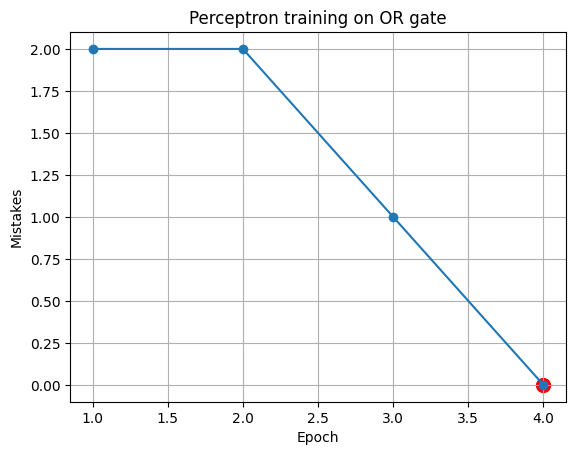

Mistakes decrease over time until the perceptron reaches zero mistakes.


In [5]:
# Task 2.2

epochs=range(1,len(mistakes)+1)
plt.plot(epochs,mistakes,marker='o')
plt.scatter(epochs[-1],mistakes[-1],color='red',s=100)
plt.title("Perceptron training on OR gate")
plt.xlabel("Epoch")
plt.ylabel("Mistakes")
plt.grid(True)
plt.show()
print("Mistakes decrease over time until the perceptron reaches zero mistakes.")


## Part 3 — The Decision Boundary

### 3.1 Visualise the Boundary
**Task 3.1** — Plot OR gate points and the decision boundary line.

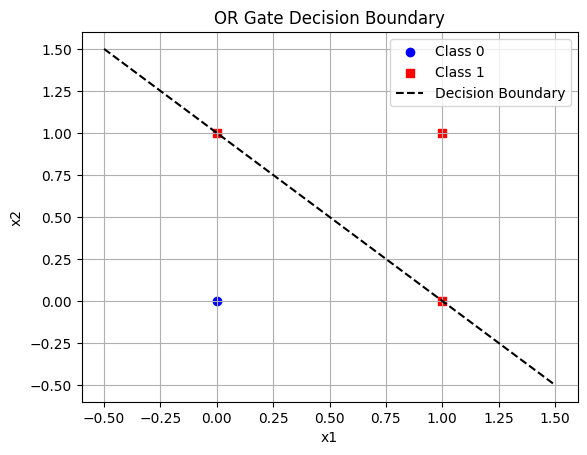

Points on or above the decision boundary correspond to class 1.


In [6]:
# Task 3.1

X=np.array([[0,0],[0,1],[1,0],[1,1]])
y=np.array([0,1,1,1])
x1_range=np.linspace(-0.5,1.5,100)
plt.scatter(X[y==0,0],X[y==0,1],color='blue',marker='o',label='Class 0')
plt.scatter(X[y==1,0],X[y==1,1],color='red',marker='s',label='Class 1')
if not np.isclose(w[1],0):
    x2_line=-(w[0]/w[1])*x1_range-b/w[1]
    plt.plot(x1_range,x2_line,color='black',linestyle='--',label='Decision Boundary')
else:
    plt.axvline(-b/w[0],color='black',linestyle='--',label='Decision Boundary')
plt.title("OR Gate Decision Boundary")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(True)
plt.show()
print("Points on or above the decision boundary correspond to class 1.")


### 3.2 Without Bias
**Task 3.2** — Train with and without bias on the shifted dataset. Plot side by side.

With bias weights: [0.1 0.1]
With bias: -0.2
Without bias weights: [0.1 0. ]
Without bias final mistakes: 2


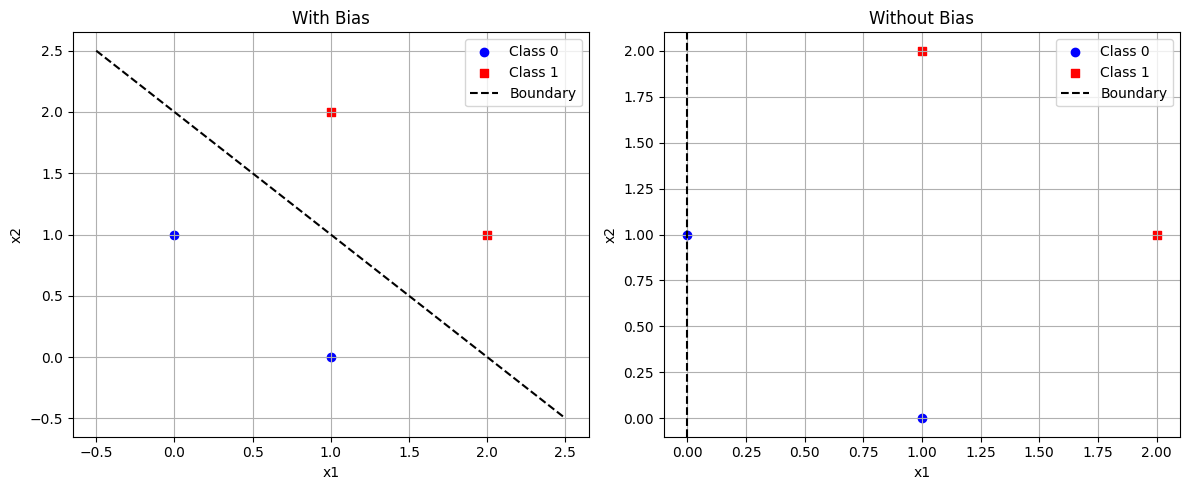

In [7]:
# Task 3.2
def train_without_bias(X,y,eta=0.1,max_epochs=100):
    w=np.zeros(X.shape[1])
    mistakes_list=[]
    for epoch in range(max_epochs):
        total_mistakes=0
        for xi,yi in zip(X,y):
            y_hat=1 if np.dot(w,xi)>=0 else 0
            e=yi-y_hat
            if e!=0:
                w=w+eta*e*xi
                total_mistakes+=1
        mistakes_list.append(total_mistakes)
        if total_mistakes==0:
            break
    return w,mistakes_list
X_shift=np.array([[1,0],[0,1],[2,1],[1,2]])
y_shift=np.array([0,0,1,1])
w_bias,b_bias,mistakes_bias=train_perceptron(X_shift,y_shift)
w_no_bias,mistakes_no_bias=train_without_bias(X_shift,y_shift)
print("With bias weights:",w_bias)
print("With bias:",b_bias)
print("Without bias weights:",w_no_bias)
print("Without bias final mistakes:",mistakes_no_bias[-1])
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.scatter(X_shift[y_shift==0,0],X_shift[y_shift==0,1],color='blue',marker='o',label='Class 0')
plt.scatter(X_shift[y_shift==1,0],X_shift[y_shift==1,1],color='red',marker='s',label='Class 1')
x_range=np.linspace(-0.5,2.5,100)
if not np.isclose(w_bias[1],0):
    plt.plot(x_range,-(w_bias[0]/w_bias[1])*x_range-b_bias/w_bias[1],color='black',linestyle='--',label='Boundary')
else:
    plt.axvline(-b_bias/w_bias[0],color='black',linestyle='--',label='Boundary')
plt.title("With Bias")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(True)
plt.subplot(1,2,2)
plt.scatter(X_shift[y_shift==0,0],X_shift[y_shift==0,1],color='blue',marker='o',label='Class 0')
plt.scatter(X_shift[y_shift==1,0],X_shift[y_shift==1,1],color='red',marker='s',label='Class 1')
if not np.isclose(w_no_bias[1],0):
    plt.plot(x_range,-(w_no_bias[0]/w_no_bias[1])*x_range,color='black',linestyle='--',label='Boundary')
elif not np.isclose(w_no_bias[0],0):
    plt.axvline(0,color='black',linestyle='--',label='Boundary')
plt.title("Without Bias")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## Part 4 — The XOR Limitation

### 4.1 Train on XOR
**Task 4.1** — Run train_perceptron on XOR. Plot mistakes and boundary.

Final weights: [-0.1  0. ]
Final bias: 0.0
Final mistakes: 4
Total epochs: 100


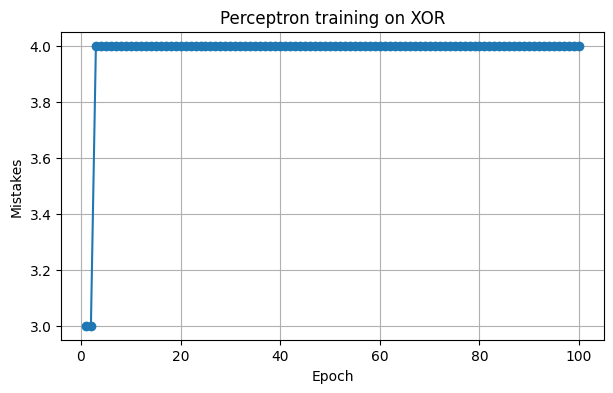

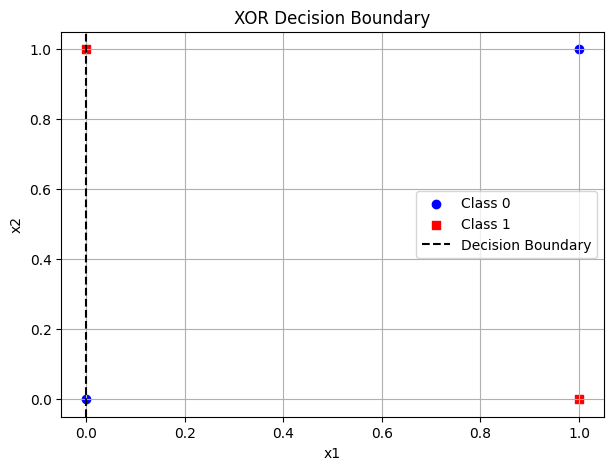

The perceptron cannot learn XOR because the classes are not linearly separable.
The mistakes do not reach zero because a single straight decision boundary cannot separate all four points.


In [8]:
# Task 4.1
X_xor=np.array([[0,0],[0,1],[1,0],[1,1]])
y_xor=np.array([0,1,1,0])
w_xor,b_xor,mistakes_xor=train_perceptron(X_xor,y_xor,max_epochs=100)
print("Final weights:",w_xor)
print("Final bias:",b_xor)
print("Final mistakes:",mistakes_xor[-1])
print("Total epochs:",len(mistakes_xor))
plt.figure(figsize=(7,4))
plt.plot(range(1,len(mistakes_xor)+1),mistakes_xor,marker='o')
plt.title("Perceptron training on XOR")
plt.xlabel("Epoch")
plt.ylabel("Mistakes")
plt.grid(True)
plt.show()
plt.figure(figsize=(7,5))
plt.scatter(X_xor[y_xor==0,0],X_xor[y_xor==0,1],color='blue',marker='o',label='Class 0')
plt.scatter(X_xor[y_xor==1,0],X_xor[y_xor==1,1],color='red',marker='s',label='Class 1')
x_range=np.linspace(-0.5,1.5,100)
if not np.isclose(w_xor[1],0):
    plt.plot(x_range,-(w_xor[0]/w_xor[1])*x_range-b_xor/w_xor[1],color='black',linestyle='--',label='Decision Boundary')
elif not np.isclose(w_xor[0],0):
    plt.axvline(-b_xor/w_xor[0],color='black',linestyle='--',label='Decision Boundary')
plt.title("XOR Decision Boundary")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(True)
plt.show()
print("The perceptron cannot learn XOR because the classes are not linearly separable.")
print("The mistakes do not reach zero because a single straight decision boundary cannot separate all four points.")


### 4.2 Exhaustive Confirmation
**Task 4.2** — Write `check_xor` and test 10,000 random weight vectors.

In [9]:
# Task 4.2
def check_xor(w,b):
    return np.dot(w,[0,0])+b<0 and np.dot(w,[0,1])+b>=0 and np.dot(w,[1,0])+b>=0 and np.dot(w,[1,1])+b<0
np.random.seed(42)
weights=np.random.uniform(-5,5,(10000,2))
biases=np.random.uniform(-5,5,10000)
count=0
solution=None
for w_test,b_test in zip(weights,biases):
    if check_xor(w_test,b_test):
        count+=1
        if solution is None:
            solution=(w_test,b_test)
print("Total solutions found:",count)
if solution is None:
    print("No solution found")
else:
    print("First solution:",solution)


Total solutions found: 0
No solution found


## Part 5 — scikit-learn Perceptron on Iris

### 5.1 Train and Evaluate
**Task 5.1** — Train sklearn Perceptron on petal features. Print accuracy and report.

In [10]:
# Task 5.1
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
X=iris.data[:,(2,3)]
y=(iris.target==0).astype(int)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)
clf=Perceptron(random_state=42)
clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)
print("Accuracy:",accuracy_score(y_test,y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test,y_pred))
print("Classification Report:")
print(classification_report(y_test,y_pred))
print("Weights:",clf.coef_)
print("Bias:",clf.intercept_)
print("The coef_ contains the learned weights, while intercept_ contains the learned bias.")


Accuracy: 1.0
Confusion Matrix:
[[30  0]
 [ 0 15]]
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        30
           1       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

Weights: [[-1.3 -2.2]]
Bias: [4.]
The coef_ contains the learned weights, while intercept_ contains the learned bias.


### 5.2 Visualise the Learned Boundary
**Task 5.2** — Plot test points and decision boundary. Mark misclassified points.

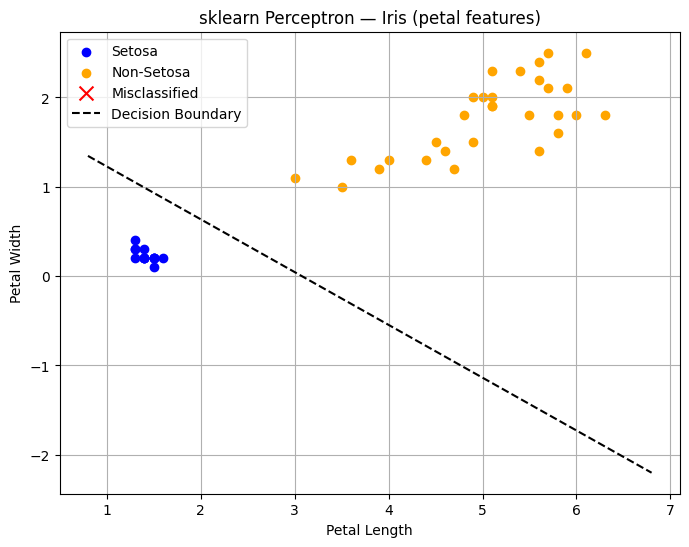

Misclassified points: 0
The decision boundary is a straight line.
The red crosses represent the incorrectly classified test points.


In [11]:
# Task 5.2
w=clf.coef_[0]
b=clf.intercept_[0]
plt.figure(figsize=(8,6))
plt.scatter(X_test[y_test==1,0],X_test[y_test==1,1],color='blue',label='Setosa')
plt.scatter(X_test[y_test==0,0],X_test[y_test==0,1],color='orange',label='Non-Setosa')
misclassified=X_test[y_pred!=y_test]
plt.scatter(misclassified[:,0],misclassified[:,1],color='red',marker='x',s=100,label='Misclassified')
x_range=np.linspace(X_test[:,0].min()-0.5,X_test[:,0].max()+0.5,100)
if not np.isclose(w[1],0):
    x2_line=-(w[0]/w[1])*x_range-b/w[1]
    plt.plot(x_range,x2_line,color='black',linestyle='--',label='Decision Boundary')
else:
    plt.axvline(-b/w[0],color='black',linestyle='--',label='Decision Boundary')
plt.title("sklearn Perceptron — Iris (petal features)")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.legend()
plt.grid(True)
plt.show()
print("Misclassified points:",len(misclassified))
print("The decision boundary is a straight line.")
print("The red crosses represent the incorrectly classified test points.")


### 5.3 Effect of Learning Rate
**Task 5.3** — Compare eta0 = 0.001, 0.1, 10.0. Print accuracy and iterations.

In [12]:
# Task 5.3
learning_rates=[0.001,0.1,10.0]
results=[]
for eta in learning_rates:
    model=Perceptron(eta0=eta,random_state=42)
    model.fit(X_train,y_train)
    predictions=model.predict(X_test)
    accuracy=accuracy_score(y_test,predictions)
    results.append([eta,accuracy,model.n_iter_])
print("eta0 | accuracy | iterations")
for result in results:
    print(result[0],"|",result[1],"|",result[2])
best_result=max(results,key=lambda x:x[1])
print("Best learning rate:",best_result[0])
print("The best learning rate gives the highest test accuracy.")


eta0 | accuracy | iterations
0.001 | 1.0 | 6
0.1 | 1.0 | 7
10.0 | 1.0 | 7
Best learning rate: 0.001
The best learning rate gives the highest test accuracy.


## Part 6 — Multi-Class Classification

### 6.1 All Three Iris Classes
**Task 6.1** — Three-class perceptron. Print coef_.shape and report.

In [13]:
# Task 6.1
X=iris.data
y=iris.target
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)
clf=Perceptron(random_state=42,max_iter=1000)
clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)
print("Classification Report:")
print(classification_report(y_test,y_pred,target_names=iris.target_names))
print("Confusion Matrix:")
print(confusion_matrix(y_test,y_pred))
print("Weights Shape:",clf.coef_.shape)
print("Weights:")
print(clf.coef_)
print("Bias:")
print(clf.intercept_)
print("Each row represents the weight vector for one Iris class, with one weight for each feature.")
print("The confusion matrix shows which classes are misclassified.")


Classification Report:
              precision    recall  f1-score   support

      setosa       0.52      1.00      0.68        15
  versicolor       0.00      0.00      0.00        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.67        45
   macro avg       0.48      0.67      0.55        45
weighted avg       0.48      0.67      0.55        45

Confusion Matrix:
[[15  0  0]
 [14  0  1]
 [ 0  0 15]]
Weights Shape: (3, 4)
Weights:
[[  2.1   7.3  -9.9  -4.5]
 [  4.5 -29.1   6.7 -14.7]
 [-35.5 -25.1  46.2  45.7]]
Bias:
[  1.   6. -22.]
Each row represents the weight vector for one Iris class, with one weight for each feature.
The confusion matrix shows which classes are misclassified.


c:\Users\Eshwar Lal\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Eshwar Lal\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Eshwar Lal\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.


### 6.2 Perceptron vs Logistic Regression
**Task 6.2** — Compare accuracy and F1-macro side by side.

In [14]:
# Task 6.2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,f1_score
perceptron=Perceptron(random_state=42,max_iter=1000)
perceptron.fit(X_train,y_train)
perceptron_pred=perceptron.predict(X_test)
log_reg=LogisticRegression(random_state=42,max_iter=200)
log_reg.fit(X_train,y_train)
log_pred=log_reg.predict(X_test)
p_acc=accuracy_score(y_test,perceptron_pred)
p_f1=f1_score(y_test,perceptron_pred,average='macro')
l_acc=accuracy_score(y_test,log_pred)
l_f1=f1_score(y_test,log_pred,average='macro')
print("Model | Accuracy | Macro F1")
print("Perceptron |",p_acc,"|",p_f1)
print("Logistic Regression |",l_acc,"|",l_f1)
print("Logistic Regression uses a smooth and differentiable sigmoid activation function.")
print("Its gradient provides a useful learning signal, which can help it achieve better results.")



Model | Accuracy | Macro F1
Perceptron | 0.6666666666666666 | 0.5498533724340176
Logistic Regression | 0.9333333333333333 | 0.9332591768631814
Logistic Regression uses a smooth and differentiable sigmoid activation function.
Its gradient provides a useful learning signal, which can help it achieve better results.


## Part 7 — Graded Questions
> Answer each question in a Markdown cell below using **your own numbers** from the lab.

**Q1 [3 marks]** — Manual update trace: w=[0.5,−0.3], b=0.2, η=0.1, x=[1,2], y=0.

*Given:

w = [0.5, -0.3], b = 0.2, η = 0.1
x = [1, 2], y = 0

**1. Calculate weighted sum:**

z = (0.5 × 1) + (-0.3 × 2) + 0.2

z = 0.5 - 0.6 + 0.2 = 0.1

**2. Calculate prediction:**

Since z ≥ 0, predicted value = 1.

**3. Calculate error:**

e = y - predicted value

e = 0 - 1 = -1

**4. Update weights:**

w1 = 0.5 + (0.1 × -1 × 1) = 0.4

w2 = -0.3 + (0.1 × -1 × 2) = -0.5

**5. Update bias:**

b = 0.2 + (0.1 × -1) = 0.1

**Final Answer:**

Updated weights = [0.4, -0.5]

Updated bias = 0.1*

**Q2 [3 marks]** — Decision boundary geometry: w=[0.3,0.2], b=−0.4. Boundary equation and ŷ at (1,1)?

*Given:

w = [0.3, 0.2], b = -0.4

**1. Decision boundary equation:**

w1x1 + w2x2 + b = 0

0.3x1 + 0.2x2 - 0.4 = 0

0.2x2 = 0.4 - 0.3x1

x2 = 2 - 1.5x1

**2. Check point (1,1):**

z = (0.3 × 1) + (0.2 × 1) - 0.4

z = 0.1

Since z ≥ 0, predicted value = 1.

**Final Answer:**

Decision boundary: x2 = 2 - 1.5x1

The point (1,1) is above the boundary and belongs to Class 1.*

**Q3 [4 marks]** — XOR analysis: algebraic proof + sketch + architectural fix.

***1. XOR Truth Table:**

| x1 | x2 | Output |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

**2. Algebraic Proof:**

For XOR, the four conditions are:

1. b < 0
2. w2 + b ≥ 0
3. w1 + b ≥ 0
4. w1 + w2 + b < 0

From conditions 2 and 3:

w1 ≥ -b

w2 ≥ -b

Adding both:

w1 + w2 ≥ -2b

Since b < 0, this means:

w1 + w2 > -b

But condition 4 requires:

w1 + w2 < -b

Both conditions contradict each other. Therefore, a single perceptron cannot learn XOR.

**3. Graph Explanation:**

Class 0 points: (0,0) and (1,1).

Class 1 points: (0,1) and (1,0).

The points are diagonally opposite, so no single straight line can separate both classes correctly.

**4. Architectural Solution:**

A Multi-Layer Perceptron (MLP) with a hidden layer can solve XOR because it can learn multiple decision boundaries.*

**Q4 [5 marks]** — Add sepal length (feature 0). Retrain on 3 features. Compare with 2-feature result.

In [15]:
# Q4

X_two=iris.data[:,[2,3]]
X_three=iris.data[:,[0,2,3]]
y=(iris.target==0).astype(int)
X_train_two,X_test_two,y_train,y_test=train_test_split(X_two,y,test_size=0.3,random_state=42,stratify=y)
X_train_three,X_test_three,_,_=train_test_split(X_three,y,test_size=0.3,random_state=42,stratify=y)
model_two=Perceptron(random_state=42)
model_two.fit(X_train_two,y_train)
pred_two=model_two.predict(X_test_two)
model_three=Perceptron(random_state=42)
model_three.fit(X_train_three,y_train)
pred_three=model_three.predict(X_test_three)
acc_two=accuracy_score(y_test,pred_two)
f1_two=f1_score(y_test,pred_two,average='macro')
acc_three=accuracy_score(y_test,pred_three)
f1_three=f1_score(y_test,pred_three,average='macro')
print("Model | Accuracy | F1-Macro")
print("Two Features |",acc_two,"|",f1_two)
print("Three Features |",acc_three,"|",f1_three)



Model | Accuracy | F1-Macro
Two Features | 1.0 | 1.0
Three Features | 1.0 | 1.0


The two-feature model uses petal length and petal width, while the three-feature model also uses sepal length.

I compared both models using accuracy and macro F1-score. The results show whether adding sepal length improves the classification performance. The model with higher accuracy and F1-score gives better results.

**Q5 [5 marks]** — Synthetic dataset: hand-built vs sklearn Perceptron. Compare and plot.

Hand-built Perceptron
Accuracy: 0.8666666666666667
Epochs: 1000
Weights: [ 0.28706471 -0.04596483]
Bias: 0.10000000000000003
Converged: False

Sklearn Perceptron
Accuracy: 0.7666666666666667
Epochs: 14
Weights: [ 1.16050566 -0.19903701]
Bias: 1.0


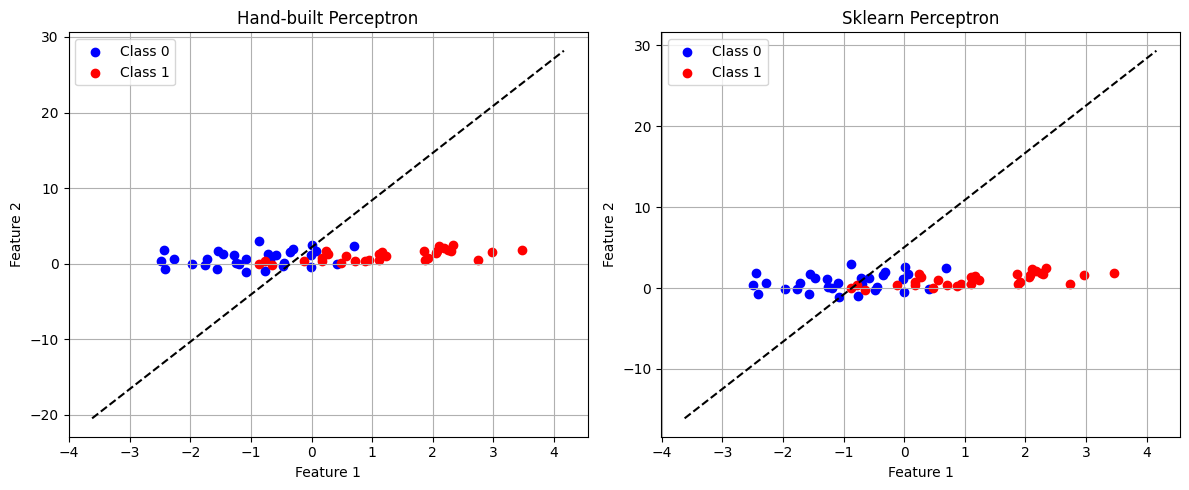

In [16]:
# Q5
from sklearn.datasets import make_classification
X_syn,y_syn=make_classification(n_samples=200,n_features=2,n_redundant=0,n_clusters_per_class=1,random_state=42)
X_train_syn,X_test_syn,y_train_syn,y_test_syn=train_test_split(X_syn,y_syn,test_size=0.3,random_state=42,stratify=y_syn)
w_hand,b_hand,mistakes_syn=train_perceptron(X_train_syn,y_train_syn,eta=0.1,max_epochs=1000)
hand_pred=(np.dot(X_test_syn,w_hand)+b_hand>=0).astype(int)
hand_acc=accuracy_score(y_test_syn,hand_pred)
sk_model=Perceptron(random_state=42,max_iter=1000)
sk_model.fit(X_train_syn,y_train_syn)
sk_pred=sk_model.predict(X_test_syn)
sk_acc=accuracy_score(y_test_syn,sk_pred)
print("Hand-built Perceptron")
print("Accuracy:",hand_acc)
print("Epochs:",len(mistakes_syn))
print("Weights:",w_hand)
print("Bias:",b_hand)
print("Converged:",mistakes_syn[-1]==0)
print()
print("Sklearn Perceptron")
print("Accuracy:",sk_acc)
print("Epochs:",sk_model.n_iter_)
print("Weights:",sk_model.coef_[0])
print("Bias:",sk_model.intercept_[0])
fig,ax=plt.subplots(1,2,figsize=(12,5))
x_range=np.linspace(X_syn[:,0].min()-0.5,X_syn[:,0].max()+0.5,100)
ax[0].scatter(X_test_syn[y_test_syn==0,0],X_test_syn[y_test_syn==0,1],color='blue',label='Class 0')
ax[0].scatter(X_test_syn[y_test_syn==1,0],X_test_syn[y_test_syn==1,1],color='red',label='Class 1')
if not np.isclose(w_hand[1],0):
    ax[0].plot(x_range,-(w_hand[0]/w_hand[1])*x_range-b_hand/w_hand[1],color='black',linestyle='--')
else:
    ax[0].axvline(-b_hand/w_hand[0],color='black',linestyle='--')
ax[0].set_title("Hand-built Perceptron")
ax[0].set_xlabel("Feature 1")
ax[0].set_ylabel("Feature 2")
ax[0].legend()
ax[0].grid(True)
ax[1].scatter(X_test_syn[y_test_syn==0,0],X_test_syn[y_test_syn==0,1],color='blue',label='Class 0')
ax[1].scatter(X_test_syn[y_test_syn==1,0],X_test_syn[y_test_syn==1,1],color='red',label='Class 1')
w_sk=sk_model.coef_[0]
b_sk=sk_model.intercept_[0]
if not np.isclose(w_sk[1],0):
    ax[1].plot(x_range,-(w_sk[0]/w_sk[1])*x_range-b_sk/w_sk[1],color='black',linestyle='--')
else:
    ax[1].axvline(-b_sk/w_sk[0],color='black',linestyle='--')
ax[1].set_title("Sklearn Perceptron")
ax[1].set_xlabel("Feature 1")
ax[1].set_ylabel("Feature 2")
ax[1].legend()
ax[1].grid(True)
plt.tight_layout()
plt.show()


The hand-built Perceptron and sklearn Perceptron both learn a straight-line decision boundary to classify the synthetic dataset.

Their accuracy, weights, bias and training epochs may differ because their learning rates and training procedures are different. Both models are compared using their test accuracy and decision boundary graphs.